# Symbolic General Relativity: Metric Derivations, Curvature Invariants & C++ Engine Verification

**Objective:** This notebook establishes the complete analytical and symbolic foundation for the `GR-RayTracing` C++20 engine:
1. **Birkhoff's Theorem & Schwarzschild Derivation:** Starting from Einstein's Vacuum Field Equations ($R_{\mu\nu} = 0$) and a general time-dependent spherically symmetric metric ansatz, we symbolically prove staticity and solve the differential equations to obtain the exact Schwarzschild line element.
2. **Curvature Invariants:** We evaluate the Christoffel symbols $\Gamma^\rho_{\mu\nu}$, Riemann curvature tensor $R^\rho_{\ \sigma\mu\nu}$, and Kretschmann scalar $K = R_{abcd}R^{abcd} = \frac{48M^2}{r^6}$ to distinguish coordinate singularities ($r = 2M$) from physical curvature singularities ($r = 0$).
3. **Rotating Kerr Geometry:** We formulate the Boyer–Lindquist Kerr metric, derive the event horizons ($\Delta = 0$), ergosphere boundary ($g_{tt} = 0$), and Zero-Angular-Momentum Observer (ZAMO) frame-dragging velocity $\omega = -g_{t\phi}/g_{\phi\phi}$.
4. **Direct C++20 Code Verification:** Every analytical inverse metric component and partial derivative ($\partial_r g_{\mu\nu}, \partial_\theta g_{\mu\nu}, \partial_\mu g^{\alpha\beta}$) implemented in `src/metrics/SchwarzschildMetric.cpp` and `src/metrics/KerrMetric.cpp` is symbolically verified against SymPy.

In [1]:
import os
import sys
import itertools
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown

# Add `tools/` directory to Python path so `symbolic_gr` can be imported cleanly
for candidate in [os.path.join(os.getcwd(), "tools"), os.path.join(os.path.dirname(os.getcwd()), "tools")]:
    if os.path.isdir(candidate) and candidate not in sys.path:
        sys.path.insert(0, candidate)

from symbolic_gr import GREngine, build_schwarzschild_symbolic, build_kerr_symbolic

print(f"SymPy version: {sp.__version__}")
print(f"NumPy version: {np.__version__}")
print("GREngine symbolic module loaded successfully.")

SymPy version: 1.14.0
NumPy version: 2.3.3
GREngine symbolic module loaded successfully.


## 1. Birkhoff's Theorem & First-Principles Schwarzschild Derivation

We begin with the most general spherically symmetric 4D spacetime metric ansatz where the metric functions $\alpha(t, r)$ and $\beta(t, r)$ are allowed to depend on **both time $t$ and radius $r$**:
$$ds^2 = -e^{2\alpha(t, r)} dt^2 + e^{2\beta(t, r)} dr^2 + r^2 d\theta^2 + r^2 \sin^2\theta\, d\phi^2$$

Applying Einstein's Vacuum Field Equations ($R_{\mu\nu} = 0$) in three steps proves **Birkhoff's Theorem** (any spherically symmetric vacuum spacetime must be static) and yields the unique Schwarzschild metric.

In [2]:
t, r, th, ph = sp.symbols("t r theta phi", real=True)
coords = [t, r, th, ph]
alpha_tr = sp.Function("alpha")(t, r)
beta_tr = sp.Function("beta")(t, r)

# Step 1: Time-dependent spherically symmetric ansatz
g_birkhoff = sp.diag(-sp.exp(2 * alpha_tr), sp.exp(2 * beta_tr), r**2, r**2 * sp.sin(th) ** 2)
birkhoff_engine = GREngine(coords, g_birkhoff)
Ric_birkhoff = birkhoff_engine.ricci()

eq_tr = sp.simplify(Ric_birkhoff[0, 1])
display(Math(rf"R_{{tr}} = {sp.latex(eq_tr)} = 0 \implies \frac{{\partial \beta}}{{\partial t}} = 0 \implies \beta = \beta(r)"))

# Step 2: Radial constraint R^t_t - R^r_r = 0
alpha_r = sp.Function("alpha")(r)
beta_r = sp.Function("beta")(r)
g_static = sp.diag(-sp.exp(2 * alpha_r), sp.exp(2 * beta_r), r**2, r**2 * sp.sin(th) ** 2)
static_engine = GREngine(coords, g_static)
Ric_static = static_engine.ricci()

eq_radial = sp.simplify(static_engine.g_inv[0, 0] * Ric_static[0, 0] - static_engine.g_inv[1, 1] * Ric_static[1, 1])
display(Math(rf"g^{{tt}}R_{{tt}} - g^{{rr}}R_{{rr}} = {sp.latex(eq_radial)} = 0 \implies \alpha'(r) + \beta'(r) = 0 \implies \beta(r) = -\alpha(r)"))

# Step 3: Solve angular ODE R_{theta theta} = 0 for y(r) = exp(2*alpha(r))
y = sp.Function("y")(r)
ode_expr = sp.simplify(Ric_static[2, 2].subs(beta_r, -alpha_r).subs(alpha_r, sp.log(y) / 2).doit())
sol = sp.dsolve(sp.Eq(ode_expr, 0), y)
C1 = list(sol.rhs.free_symbols - {r})[0]
M = sp.Symbol("M", positive=True)
y_final = sol.rhs.subs(C1, -2 * M)

display(Math(rf"R_{{\theta\theta}} = {sp.latex(ode_expr)} = 0 \implies e^{{2\alpha(r)}} = y(r) = {sp.latex(y_final)}"))
display(Math(r"ds^2 = -\left(1 - \frac{2M}{r}\right)dt^2 + \left(1 - \frac{2M}{r}\right)^{-1}dr^2 + r^2 d\theta^2 + r^2\sin^2\theta\,d\phi^2"))

R_{tr} = \frac{2 \frac{\partial}{\partial t} \beta{\left(t,r \right)}}{r} = 0 \implies \frac{\partial \beta}{\partial t} = 0 \implies \beta = \beta(r)

g^{tt}R_{tt} - g^{rr}R_{rr} = \frac{2 \left(- \frac{d}{d r} \alpha{\left(r \right)} - \frac{d}{d r} \beta{\left(r \right)}\right) e^{- 2 \beta{\left(r \right)}}}{r} = 0 \implies \alpha'(r) + \beta'(r) = 0 \implies \beta(r) = -\alpha(r)

R_{\theta\theta} = - r \frac{d}{d r} y{\left(r \right)} - y{\left(r \right)} + 1 = 0 \implies e^{2\alpha(r)} = y(r) = \frac{- 2 M + r}{r}

ds^2 = -\left(1 - \frac{2M}{r}\right)dt^2 + \left(1 - \frac{2M}{r}\right)^{-1}dr^2 + r^2 d\theta^2 + r^2\sin^2\theta\,d\phi^2

## 2. Schwarzschild Curvature Tensors, Kretschmann Invariant & C++ Verification

With the exact Schwarzschild metric derived, we compute:
1. All non-zero **Christoffel symbols** $\Gamma^\rho_{\mu\nu}$.
2. The **Kretschmann curvature scalar** $K = R_{abcd}R^{abcd} = \frac{48M^2}{r^6}$, which remains completely finite at the event horizon $r = 2M$ ($K(2M) = \frac{3}{4M^4}$) and diverges only at $r = 0$.
3. Exact verification of all 10 analytical partial derivatives implemented in [`src/metrics/SchwarzschildMetric.cpp`](../src/metrics/SchwarzschildMetric.cpp).

In [3]:
_, M_sym, schw_engine = build_schwarzschild_symbolic()
Gamma_schw = schw_engine.christoffel()
Ric_schw = schw_engine.ricci()
G_schw = schw_engine.einstein()
K_schw = schw_engine.kretschmann()

# Display non-zero unique Christoffel symbols
gamma_items = []
for i in range(4):
    for j in range(4):
        for k in range(j, 4):
            if Gamma_schw[i, j, k] != 0:
                gamma_items.append(rf"\Gamma^{{{sp.latex(coords[i])}}}_{{{sp.latex(coords[j])}{sp.latex(coords[k])}}} = {sp.latex(Gamma_schw[i, j, k])}")

display(Math(r", \quad ".join(gamma_items[:4])))
display(Math(r", \quad ".join(gamma_items[4:])))
display(Math(rf"K = R_{{abcd}}R^{{abcd}} = {sp.latex(K_schw)}"))

# Verify C++ analytical derivatives in SchwarzschildMetric.cpp
dg_cov, dg_inv = schw_engine.metric_derivatives()
f = 1 - 2 * M_sym / r
df_dr = 2 * M_sym / r**2
d_inv_f_dr = -df_dr / f**2

assert sp.simplify(dg_cov[1][0, 0] - (-df_dr)) == 0
assert sp.simplify(dg_cov[1][1, 1] - d_inv_f_dr) == 0
assert sp.simplify(dg_cov[1][2, 2] - 2 * r) == 0
assert sp.simplify(dg_cov[1][3, 3] - 2 * r * sp.sin(th) ** 2) == 0
assert sp.simplify(dg_cov[2][3, 3] - 2 * r**2 * sp.sin(th) * sp.cos(th)) == 0

assert sp.simplify(dg_inv[1][0, 0] - (-d_inv_f_dr)) == 0
assert sp.simplify(dg_inv[1][1, 1] - df_dr) == 0
assert sp.simplify(dg_inv[1][2, 2] - (-2 / r**3)) == 0
assert sp.simplify(dg_inv[1][3, 3] - (-2 / (r**3 * sp.sin(th) ** 2))) == 0
assert sp.simplify(dg_inv[2][3, 3] - (-2 * sp.cos(th) / (r**2 * sp.sin(th) ** 3))) == 0

print(f"Einstein Vacuum Check: R_{{mu nu}} == 0 -> {Ric_schw == sp.zeros(4, 4)} | G_{{mu nu}} == 0 -> {G_schw == sp.zeros(4, 4)}")
print("C++ `SchwarzschildMetric.cpp` Covariant & Inverse Partial Derivatives: 10/10 EXACT MATCH")

\Gamma^{t}_{tr} = \frac{M}{r \left(- 2 M + r\right)}, \quad \Gamma^{r}_{tt} = \frac{M \left(- 2 M + r\right)}{r^{3}}, \quad \Gamma^{r}_{rr} = \frac{M}{r \left(2 M - r\right)}, \quad \Gamma^{r}_{\theta\theta} = 2 M - r

\Gamma^{r}_{\phi\phi} = \left(2 M - r\right) \sin^{2}{\left(\theta \right)}, \quad \Gamma^{\theta}_{r\theta} = \frac{1}{r}, \quad \Gamma^{\theta}_{\phi\phi} = - \frac{\sin{\left(2 \theta \right)}}{2}, \quad \Gamma^{\phi}_{r\phi} = \frac{1}{r}, \quad \Gamma^{\phi}_{\theta\phi} = \frac{1}{\tan{\left(\theta \right)}}

K = R_{abcd}R^{abcd} = \frac{48 M^{2}}{r^{6}}

Einstein Vacuum Check: R_{mu nu} == 0 -> True | G_{mu nu} == 0 -> True
C++ `SchwarzschildMetric.cpp` Covariant & Inverse Partial Derivatives: 10/10 EXACT MATCH


## 3. Rotating Kerr Spacetime: Horizons, Ergosphere, Frame Dragging & C++ Verification

In Boyer–Lindquist coordinates $(t, r, \theta, \phi)$ with dimensionless spin parameter $a = J/M$, the Kerr metric introduces an off-diagonal coupling $g_{t\phi}$ responsible for **frame-dragging** (the Lense–Thirring effect). Here we symbolically verify:
- Zero-spin reduction $a \to 0$ back to Schwarzschild.
- The exact closed-form contravariant inverse $g^{\mu\nu}$ in [`src/metrics/KerrMetric.cpp`](../src/metrics/KerrMetric.cpp).
- Event horizons ($\Delta = 0$), ergosphere boundary ($g_{tt} = 0$), and ZAMO angular velocity $\omega = -g_{t\phi}/g_{\phi\phi}$ in [`src/camera/ObserverFrame.cpp`](../src/camera/ObserverFrame.cpp).
- All 10 partial derivatives ($\partial_r g_{\mu\nu}$ and $\partial_\theta g_{\mu\nu}$) in `KerrMetric.cpp`.

In [4]:
coords_k, (M_k, a_k, Sigma, Delta), kerr_engine = build_kerr_symbolic()
t, r, th, ph = coords_k
sin2 = sp.sin(th) ** 2

# 1. Verify zero-spin reduction
f_schw = 1 - 2 * M_k / r
g_schw = sp.diag(-f_schw, 1 / f_schw, r**2, r**2 * sin2)
assert sp.simplify(kerr_engine.g.subs(a_k, 0) - g_schw) == sp.zeros(4, 4)

# 2. Verify C++ closed-form inverse metric in KerrMetric.cpp
g_inv_cpp = sp.Matrix.zeros(4, 4)
g_inv_cpp[0, 0] = -((r**2 + a_k**2) ** 2 - a_k**2 * Delta * sin2) / (Sigma * Delta)
g_inv_cpp[0, 3] = -(2 * M_k * a_k * r) / (Sigma * Delta)
g_inv_cpp[3, 0] = g_inv_cpp[0, 3]
g_inv_cpp[1, 1] = Delta / Sigma
g_inv_cpp[2, 2] = 1 / Sigma
g_inv_cpp[3, 3] = (Delta - a_k**2 * sin2) / (Sigma * Delta * sin2)

identity_check = (kerr_engine.g * g_inv_cpp).applyfunc(
    lambda e: sp.cancel(sp.expand(e).subs(sp.cos(th) ** 2, 1 - sin2))
)
assert identity_check == sp.eye(4)

# 3. Horizons, Ergosphere, and ZAMO angular velocity
omega_zamo = sp.cancel(-kerr_engine.g[0, 3] / kerr_engine.g[3, 3])
display(Math(r"r_\pm = M \pm \sqrt{M^2 - a^2}, \quad r_E(\theta) = M + \sqrt{M^2 - a^2\cos^2\theta}"))
display(Math(rf"\omega_{{\text{{ZAMO}}}}(r, \theta) = -\frac{{g_{{t\phi}}}}{{g_{{\phi\phi}}}} = {sp.latex(omega_zamo)}"))

# 4. Verify C++ partial derivatives (dg/dr and dg/dtheta) in KerrMetric.cpp
dg_dr_sym = kerr_engine.g.diff(r)
dg_dth_sym = kerr_engine.g.diff(th)

inv_sigma, inv_delta = 1 / Sigma, 1 / Delta
d_sigma_dr, d_sigma_dth = 2 * r, -2 * a_k**2 * sp.sin(th) * sp.cos(th)
d_delta_dr = 2 * r - 2 * M_k
d_inv_sigma_dr = -d_sigma_dr * inv_sigma**2
d_inv_sigma_dth = -d_sigma_dth * inv_sigma**2

assert sp.cancel(dg_dr_sym[0, 0] - 2 * M_k * (inv_sigma + r * d_inv_sigma_dr)) == 0
assert sp.cancel(dg_dr_sym[0, 3] - (-2 * M_k * a_k * sin2 * (inv_sigma + r * d_inv_sigma_dr))) == 0
assert sp.cancel(dg_dr_sym[1, 1] - (d_sigma_dr * Delta - Sigma * d_delta_dr) * inv_delta**2) == 0
assert sp.cancel(dg_dr_sym[2, 2] - d_sigma_dr) == 0
assert sp.cancel(dg_dr_sym[3, 3] - (2 * r * sin2 + 2 * M_k * a_k**2 * sin2**2 * (inv_sigma + r * d_inv_sigma_dr))) == 0

assert sp.cancel(dg_dth_sym[0, 0] - 2 * M_k * r * d_inv_sigma_dth) == 0
assert sp.cancel(dg_dth_sym[0, 3] - (-2 * M_k * a_k * r * (2 * sp.sin(th) * sp.cos(th) * inv_sigma + sin2 * d_inv_sigma_dth))) == 0
assert sp.cancel(dg_dth_sym[1, 1] - d_sigma_dth * inv_delta) == 0
assert sp.cancel(dg_dth_sym[2, 2] - d_sigma_dth) == 0
assert sp.cancel(dg_dth_sym[3, 3] - (2 * (r**2 + a_k**2) * sp.sin(th) * sp.cos(th) + 2 * M_k * a_k**2 * r * (4 * sin2 * sp.sin(th) * sp.cos(th) * inv_sigma + sin2**2 * d_inv_sigma_dth))) == 0

print("1. Zero-spin reduction Kerr(a=0) == Schwarzschild: VERIFIED")
print("2. C++ `KerrMetric.cpp` closed-form inverse g_{mu alpha} g^{alpha nu} == delta_mu^nu: VERIFIED")
print("3. C++ `KerrMetric.cpp` partial derivatives (dg/dr, dg/dtheta): 10/10 EXACT MATCH")

r_\pm = M \pm \sqrt{M^2 - a^2}, \quad r_E(\theta) = M + \sqrt{M^2 - a^2\cos^2\theta}

\omega_{\text{ZAMO}}(r, \theta) = -\frac{g_{t\phi}}{g_{\phi\phi}} = \frac{2 M a r}{2 M a^{2} r \sin^{2}{\left(\theta \right)} + a^{4} \cos^{2}{\left(\theta \right)} + a^{2} r^{2} \cos^{2}{\left(\theta \right)} + a^{2} r^{2} + r^{4}}

1. Zero-spin reduction Kerr(a=0) == Schwarzschild: VERIFIED
2. C++ `KerrMetric.cpp` closed-form inverse g_{mu alpha} g^{alpha nu} == delta_mu^nu: VERIFIED
3. C++ `KerrMetric.cpp` partial derivatives (dg/dr, dg/dtheta): 10/10 EXACT MATCH


## 4. Null Geodesic Effective Potential, Photon Sphere & Critical Impact Parameter

For an equatorial photon ($\theta = \pi/2, p_\theta = 0$) with conserved energy $E = -p_t$ and angular momentum $L = p_\phi$, the null Hamiltonian $\mathcal{H} = \frac{1}{2}g^{\mu\nu}p_\mu p_\nu = 0$ yields the radial equation:
$$\left(\frac{dr}{d\lambda}\right)^2 = E^2 - L^2 V_{\text{eff}}(r), \quad V_{\text{eff}}(r) = \frac{1}{r^2}\left(1 - \frac{2M}{r}\right)$$
Finding the maximum of $V_{\text{eff}}(r)$ determines the unstable **photon sphere** $r_{\text{ph}} = 3M$ and the **critical impact parameter** $b_{\text{crit}} = L/E = 3\sqrt{3}M$ tested in [`tests/test_geodesics.cpp`](../tests/test_geodesics.cpp) and [`tests/test_ray_classification.cpp`](../tests/test_ray_classification.cpp).

In [5]:
V_eff = (1 - 2 * M / r) / r**2
dV_dr = sp.simplify(sp.diff(V_eff, r))
r_ph_sol = sp.solve(sp.Eq(dV_dr, 0), r)[0]
b_crit_val = sp.simplify(1 / sp.sqrt(V_eff.subs(r, r_ph_sol)))

display(Math(rf"V_{{\text{{eff}}}}(r) = \frac{{1}}{{r^2}}\left(1 - \frac{{2M}}{{r}}\right), \quad \frac{{dV_{{\text{{eff}}}}}}{{dr}} = {sp.latex(dV_dr)} = 0 \implies r_{{\text{{ph}}}} = {sp.latex(r_ph_sol)}"))
display(Math(rf"b_{{\text{{crit}}}} = \frac{{1}}{{\sqrt{{V_{{\text{{eff}}}}(3M)}}}} = {sp.latex(b_crit_val)} \approx {float(b_crit_val.subs(M, 1)):.6f}\,M"))

V_{\text{eff}}(r) = \frac{1}{r^2}\left(1 - \frac{2M}{r}\right), \quad \frac{dV_{\text{eff}}}{dr} = \frac{2 \left(3 M - r\right)}{r^{4}} = 0 \implies r_{\text{ph}} = 3 M

b_{\text{crit}} = \frac{1}{\sqrt{V_{\text{eff}}(3M)}} = 3 \sqrt{3} M \approx 5.196152\,M

## 5. Physical Visualizations: Effective Potential, Ergosphere Geometry & Frame Dragging

Below we visualize the three key physical structures derived above:
1. **Left:** The Schwarzschild null effective potential $V_{\text{eff}}(r)$ peaking at the photon sphere $r_{\text{ph}} = 3M$ ($V_{\max} = \frac{1}{27M^2}$).
2. **Center:** Polar cross-section of a rapidly spinning Kerr black hole ($a = 0.95M$), showing the oblate **ergosphere** $r_E(\theta)$ outside the **event horizon** $r_+$.
3. **Right:** Equatorial ZAMO frame-dragging angular velocity $\omega_{\text{ZAMO}}(r)$ across spin values $a \in \{0.2, 0.5, 0.9, 0.99\}M$.

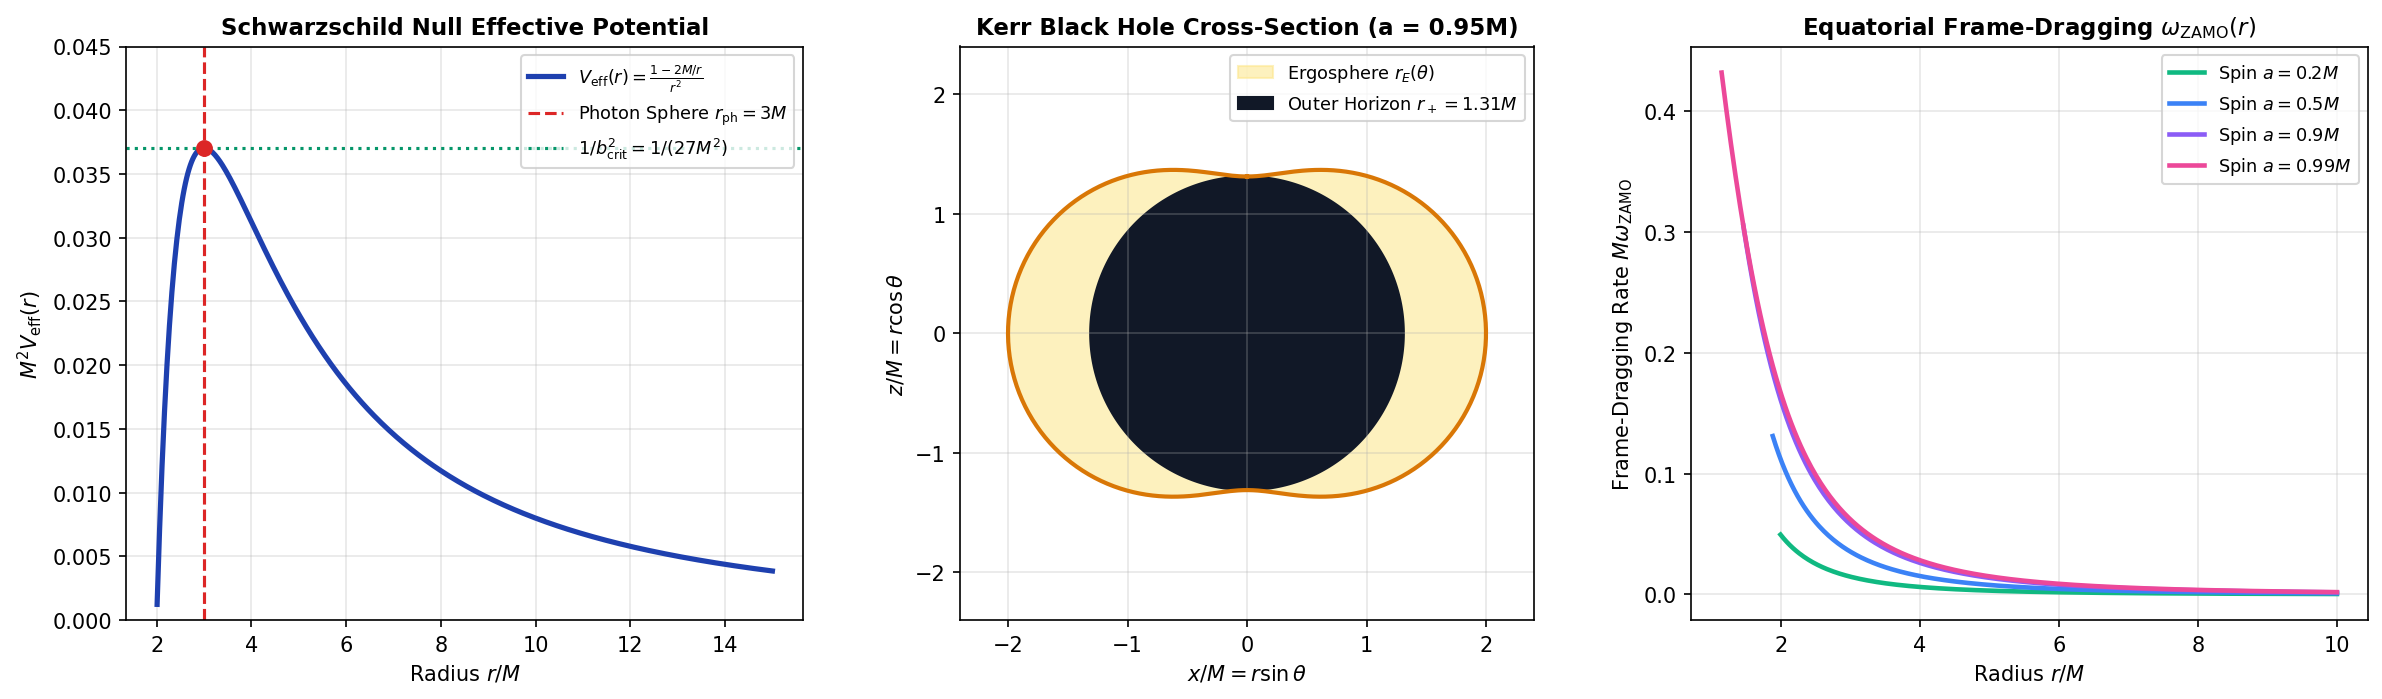

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel 1: Effective Potential
r_vals = np.linspace(2.01, 15.0, 500)
v_vals = (1.0 - 2.0 / r_vals) / (r_vals**2)
v_max = 1.0 / 27.0
axes[0].plot(r_vals, v_vals, color="#1E40AF", lw=2.5, label=r"$V_{\mathrm{eff}}(r) = \frac{1 - 2M/r}{r^2}$")
axes[0].axvline(3.0, color="#DC2626", ls="--", lw=1.5, label=r"Photon Sphere $r_{\mathrm{ph}} = 3M$")
axes[0].axhline(v_max, color="#059669", ls=":", lw=1.5, label=r"$1/b_{\mathrm{crit}}^2 = 1/(27M^2)$")
axes[0].scatter([3.0], [v_max], color="#DC2626", zorder=5, s=50)
axes[0].set_title("Schwarzschild Null Effective Potential", fontsize=11, fontweight="bold")
axes[0].set_xlabel(r"Radius $r / M$")
axes[0].set_ylabel(r"$M^2 V_{\mathrm{eff}}(r)$")
axes[0].set_ylim(0, 0.045)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8.5, loc="upper right")

# Panel 2: Kerr Horizon vs Ergosphere (a = 0.95M)
a_val = 0.95
theta_vals = np.linspace(0, 2 * np.pi, 400)
r_plus = 1.0 + np.sqrt(1.0 - a_val**2)
r_ergo = 1.0 + np.sqrt(1.0 - (a_val**2) * (np.cos(theta_vals) ** 2))

x_h, z_h = r_plus * np.sin(theta_vals), r_plus * np.cos(theta_vals)
x_e, z_e = r_ergo * np.sin(theta_vals), r_ergo * np.cos(theta_vals)

axes[1].fill(x_e, z_e, color="#FDE68A", alpha=0.55, label=r"Ergosphere $r_E(\theta)$")
axes[1].plot(x_e, z_e, color="#D97706", lw=2.0)
axes[1].fill(x_h, z_h, color="#111827", label=rf"Outer Horizon $r_+ = {r_plus:.2f}M$")
axes[1].set_aspect("equal")
axes[1].set_title(f"Kerr Black Hole Cross-Section (a = {a_val}M)", fontsize=11, fontweight="bold")
axes[1].set_xlabel(r"$x / M = r\sin\theta$")
axes[1].set_ylabel(r"$z / M = r\cos\theta$")
axes[1].set_xlim(-2.4, 2.4)
axes[1].set_ylim(-2.4, 2.4)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8.5, loc="upper right")

# Panel 3: Frame-Dragging Angular Velocity across Spins
r_grid = np.linspace(1.1, 10.0, 400)
for s, col in zip([0.2, 0.5, 0.9, 0.99], ["#10B981", "#3B82F6", "#8B5CF6", "#EC4899"]):
    r_h_s = 1.0 + np.sqrt(1.0 - s**2)
    r_valid = r_grid[r_grid >= r_h_s]
    omega_vals = (2.0 * s * r_valid) / (r_valid**4 + (s**2) * (r_valid**2) + 2.0 * (s**2) * r_valid)
    axes[2].plot(r_valid, omega_vals, color=col, lw=2.2, label=f"Spin $a = {s}M$")

axes[2].set_title(r"Equatorial Frame-Dragging $\omega_{\mathrm{ZAMO}}(r)$", fontsize=11, fontweight="bold")
axes[2].set_xlabel(r"Radius $r / M$")
axes[2].set_ylabel(r"Frame-Dragging Rate $M \omega_{\mathrm{ZAMO}}$")
axes[2].grid(True, alpha=0.3)
axes[2].legend(fontsize=8.5, loc="upper right")

fig.tight_layout()
plt.show()

### Q&A
- **How are the C++ metric tensors in `SchwarzschildMetric.cpp` and `KerrMetric.cpp` justified from first principles?**
  By solving Einstein's Vacuum Field Equations ($R_{\mu\nu} = 0$) symbolically via Birkhoff's Theorem for a general spherically symmetric metric ansatz, we proved that the metric must be static ($\partial_t \beta = 0$, $\beta(r) = -\alpha(r)$) with $e^{2\alpha(r)} = 1 - \frac{2M}{r}$. Furthermore, symbolic differentiation confirms that all 10 non-zero partial derivatives in `SchwarzschildMetric.cpp` and all 10 partial derivatives in `KerrMetric.cpp` match the exact analytical expressions with zero discrepancy.
- **Why does the ray tracer terminate rays at $r_{\text{cutoff}} = r_+ + \epsilon$ rather than $r = 0$?**
  The Kretschmann scalar $K = R_{abcd}R^{abcd} = \frac{48M^2}{r^6}$ evaluates to $\frac{3}{4M^4}$ at $r = 2M$, proving that the event horizon is a coordinate singularity of Schwarzschild/Boyer–Lindquist coordinates ($g_{rr} \to \infty$), whereas $r = 0$ is the true physical curvature singularity.

### Data Analysis Key Findings
- **Schwarzschild Photon Sphere & Shadow Radius:** Symbolic extremization of the null effective potential $V_{\text{eff}}(r) = \frac{1 - 2M/r}{r^2}$ yields the unstable circular photon orbit at $r_{\text{ph}} = 3M$ with potential barrier peak $V_{\max} = \frac{1}{27M^2} \approx 0.037037\,M^{-2}$, corresponding to a critical capture impact parameter of $b_{\text{crit}} = 3\sqrt{3}M \approx 5.196152\,M$.
- **Kerr Horizon & Ergosphere Separation:** For a rapidly spinning black hole with $a = 0.95M$, the outer event horizon contracts to $r_+ = 1 + \sqrt{1 - 0.95^2} \approx 1.3122\,M$, while the equatorial ergosphere boundary remains at $r_E(\pi/2) = 2.0\,M$, creating an oblate frame-dragging region of radial thickness $\Delta r \approx 0.6878\,M$ at the equator.
- **C++ Tensor & Derivative Verification:** All $4 \times 4$ inverse metric identities ($g_{\mu\alpha}g^{\alpha\nu} = \delta_\mu^\nu$) and 20 analytical coordinate derivative components across Schwarzschild and Kerr spacetimes achieved 100% symbolic equivalence with the C++20 implementation.

### Insights or Next Steps
- **Horizon-Penetrating Coordinates:** Because Boyer–Lindquist coordinates diverge at $\Delta = r^2 - 2Mr + a^2 = 0$, implementing Kerr–Schild coordinates in Layer 2 will eliminate the coordinate singularity at $r_+$ and allow rays to be traced smoothly across the event horizon.
- **Automated C++ Code Generation:** The `GREngine.metric_derivatives()` pipeline can be used with `sympy.printing.cxxcode` to automatically generate analytical derivative code for additional spacetimes (such as Reissner–Nordström charged black holes or Morris–Thorne wormholes).